# Plot Maps of the Service Territory for the Load Areas Modelled


In [3]:
# Start by importing the packages we need:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

from mpl_toolkits.axes_grid1 import make_axes_locatable


## Set the Directory Structure


In [11]:
# Identify the data and impage input and output directories:
load_area_mapping_data_input_directory = '/Users/burl878/Documents/Code/code_repos/esp_forecasting_loads/data/'
county_shapefile_input_directory = '/Users/burl878/Documents/Code/code_repos/esp_forecasting_loads/data/county_shapefiles/'
state_shapefile_input_directory = '/Users/burl878/Documents/Code/code_repos/esp_forecasting_loads/data/state_shapefiles/'
load_to_process_input_directory = '/Users/burl878/Documents/Code/code_repos/esp_forecasting_loads/data/'
image_output_directory = '/Users/burl878/Documents/Code/code_repos/esp_forecasting_loads/figures/ba_service_territory/'


## Set the List of Load Areas to Plot

Load areas used in this analysis are controlled by a master file `wecc_load_areas.csv` stored in the `/data` directory.


In [20]:
# Read in the BA mapping file:
load_area_list_df = pd.read_csv((load_to_process_input_directory + 'wecc_load_areas.csv'), index_col=None, header=0)

# Return the list of BAs to process/plot:
load_area_list_df


,ba,is_subregion,eia930_name,long_name
0,AVA,False,AVA,Avista Corporation
1,AZPS,False,AZPS,Arizona Public Service Company
2,BANC,False,BANC,Balancing Authority of Northern California
3,BPAT,False,BPAT,Bonneville Power Administration
4,CHPD,False,CHPD,Public Utility District 1 of Chelan County
5,CISO_PGE,True,PGAE,CISO Pacific Gas and Electric
6,CISO_SCE,True,SCE,CISO Southern California Edison
7,CISO_SDGE,True,SDGE,CISO San Diego Gas and Electric
8,CISO_VEA,True,VEA,CISO Valley Electric Association
9,DOPD,False,DOPD,Public Utility District 1 of Douglas County


## Plot the Service Territory for Each Load Area


In [14]:
# Define a function to plot the service territory for a given load area:
def plot_load_area_service_territory(load_area_to_plot: str, interconnection: str,
                                     load_area_mapping_data_input_directory: str, county_shapefile_input_directory: str, state_shapefile_input_directory: str,
                                     image_output_directory: str, image_resolution: int, save_images=False):

    # Read in the county shapefile and reassign the 'FIPS' variable as integers:
    counties_df = gpd.read_file((county_shapefile_input_directory + 'tl_2020_us_county.shp')).rename(columns={'GEOID': 'county_fips'})
    counties_df['county_fips'] = counties_df['county_fips'].astype(int)

    # Read in the state shapefile:
    states_df = gpd.read_file((state_shapefile_input_directory + 'tl_2020_us_state.shp'))
    
    # Read in the load area to county mapping file:
    if interconnection == 'EI':
       mapping_df = pd.read_csv((load_area_mapping_data_input_directory + 'ei_county_mapping.csv'))
    elif interconnection == 'WECC':
       mapping_df = pd.read_csv((load_area_mapping_data_input_directory + 'wecc_county_mapping.csv'))

    # Merge the mapping_df and counties_df together using county FIPS codes to join them:
    counties_df = counties_df.merge(mapping_df, on='county_fips', how='left')

    # Subset to only the load area you want to plot:
    counties_subset_df = counties_df.loc[counties_df['ba'] == load_area_to_plot]
    
    # Create the figure:
    fig, ax = plt.subplots(1, 1, figsize=(25, 10))
    divider = make_axes_locatable(ax)
        
    # Plot the state boundaries:
    states_df.plot(ax=ax, facecolor='none', edgecolor='black', linewidth=1, zorder=2)
    
    # Plot the county-level populations for counties in that load area:
    if not counties_subset_df.empty:
           cax = divider.append_axes("right", size="2%", pad=0.9)
           counties_subset_df.plot(column = 'population_weight',
                                   cmap = 'Purples',
                                   ax = ax,
                                   cax = cax,
                                   edgecolor = 'grey',
                                   linewidth = 0.5,
                                   legend = True,
                                   legend_kwds = {'label': ('County Population Weight in 2020'), 'orientation': 'vertical'},
                                   zorder = 1)
    
    # Set the axis limits, :
    if interconnection == 'EI':
       ax.set_xlim(-110, -66.5)
       ax.set_ylim(23.5, 50)
    elif interconnection == 'WECC':
       ax.set_xlim(-125.5, -101)
       ax.set_ylim(30, 50)
            
    # Add a title, a legend, and clean up the plot:
    ax.set_axis_off()
    ax.set_title((load_area_to_plot + ' Service Territory'), fontsize = 21)
    
    # If the "save_images" flag is set to true then save the plot to a .png file:
    if save_images == True:
       filename = (image_output_directory + load_area_to_plot + '.png') 
       plt.savefig(filename, dpi=image_resolution, bbox_inches='tight')
       plt.close()


## Test the Function


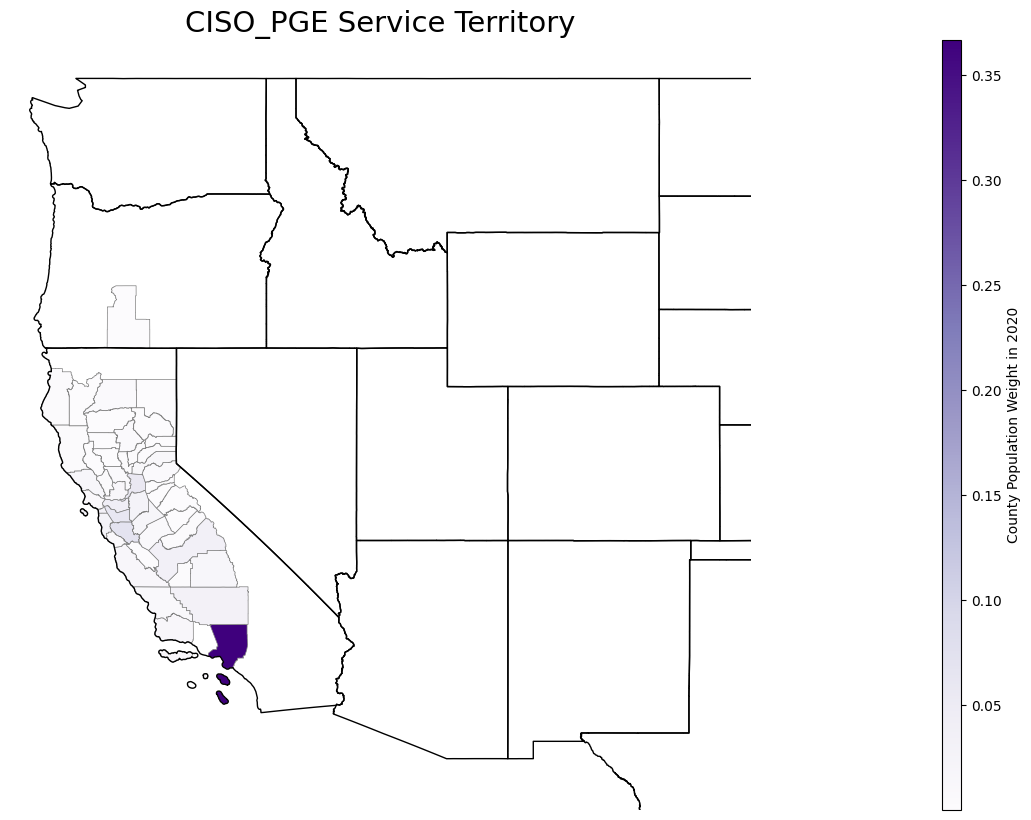

In [19]:
plot_load_area_service_territory(load_area_to_plot = 'CISO_PGE',
                                 interconnection = 'WECC',
                                 load_area_mapping_data_input_directory = load_area_mapping_data_input_directory, 
                                 county_shapefile_input_directory = county_shapefile_input_directory,
                                 state_shapefile_input_directory = state_shapefile_input_directory,
                                 image_output_directory = image_output_directory, 
                                 image_resolution = 150, 
                                 save_images = False)


## Loop Over the Load Areas and Make the Plot for Each


In [ ]:
# Make a list of all the unique load areas:
load_areas = load_area_list_df['ba'].unique()

for load_area in load_areas:
    plot_load_area_service_territory(load_area_to_plot = load_area,
                                     interconnection = 'WECC',
                                     load_area_mapping_data_input_directory = load_area_mapping_data_input_directory, 
                                     county_shapefile_input_directory = county_shapefile_input_directory,
                                     state_shapefile_input_directory = state_shapefile_input_directory,
                                     image_output_directory = image_output_directory, 
                                     image_resolution = 150, 
                                     save_images = True)
    